# Etapa 4: estudo da SVM

Entrada: `data/processed/renda.csv`. Protocolo e pré-processamento de `src/avaliacao.py`; modelos e grades de `src/svm.py`.

Esta etapa estuda a SVM numa divisão só (seed 0: 24.111 pessoas de treino, 6.028 de teste), para entender o modelo e escolher a grade de hiperparâmetros. A comparação com as referências, em 10 seeds, fica na etapa 5.

1. Como a SVM decide: a distância à fronteira
2. Os kernels: linear, RBF e polinomial
3. O mapa C × gamma do kernel RBF
4. A curva do C na SVM linear
5. Com e sem padronização
6. Vetores de suporte
7. Tempo de treino por tamanho do treino
8. Pesos por classe (`class_weight`)

Todos os tempos são medidos num único núcleo, como nas etapas anteriores.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

from src import avaliacao, config, svm

X, y = avaliacao.carregar()
X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, seed=0)
print("treino:", X_tr.shape, "| teste:", X_te.shape)


def avaliar(modelos):
    """Treina e avalia cada modelo na seed 0 com o protocolo comum. Uma linha por modelo."""
    linhas = {}
    for nome, modelo in modelos.items():
        metricas, _ = avaliacao.treinar_e_medir(modelo, X_tr, y_tr, X_te, y_te)
        linhas[nome] = metricas
    tabela = pd.DataFrame(linhas).T
    for m in ["acurácia", "F1 macro", "F1 >50K", "AUC"]:
        tabela[m] = (100 * tabela[m].astype(float)).round(1)
    tabela["tempo de treino (s)"] = tabela["tempo de treino (s)"].astype(float).round(2)
    colunas = ["acurácia", "F1 macro", "F1 >50K", "AUC", "falsos positivos", "falsos negativos",
               "tempo de treino (s)"] + (["vetores de suporte"] if "vetores de suporte" in tabela else [])
    return tabela[colunas]


avaliar({"aquecimento": svm.svm()});  # primeira execução descartada

treino: (24111, 10) | teste: (6028, 10)


## 1. Como a SVM decide: a distância à fronteira

A SVM não calcula uma probabilidade. Ela calcula, para cada pessoa, um número com sinal: a distância (em unidades da margem) até a fronteira. Positivo, o modelo responde >50K; negativo, `<=50K`. Na margem, o valor é ±1. É esse número, o `decision_function`, que a AUC usa: ela só precisa de uma nota que ordene as pessoas, não de uma probabilidade.

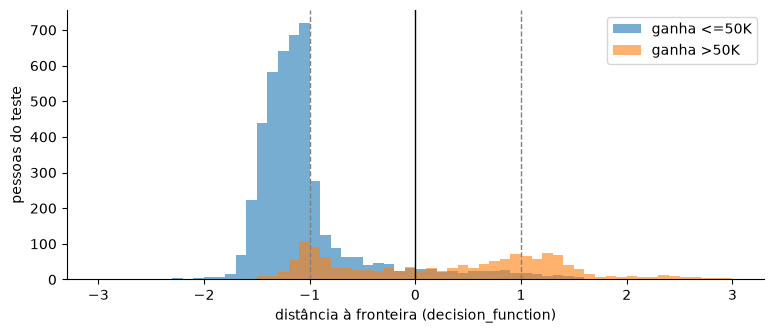

na faixa da margem (entre −1 e +1): 30.4% das pessoas do teste
vetores de suporte por classe (<=50K, >50K): [4232 3999]


In [2]:
modelo = svm.svm().fit(X_tr, y_tr)  # kernel RBF, C = 1, gamma padrão
distancia = modelo.decision_function(X_te)

fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.linspace(-3, 3, 61)
ax.hist(distancia[y_te == 0], bins=bins, alpha=0.6, color="tab:blue", label="ganha <=50K")
ax.hist(distancia[y_te == 1], bins=bins, alpha=0.6, color="tab:orange", label="ganha >50K")
ax.axvline(0, color="black", linewidth=1)
for lado in (-1, 1):
    ax.axvline(lado, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("distância à fronteira (decision_function)")
ax.set_ylabel("pessoas do teste")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(f"na faixa da margem (entre −1 e +1): {np.mean(np.abs(distancia) < 1) * 100:.1f}% das pessoas do teste")
print("vetores de suporte por classe (<=50K, >50K):", modelo.named_steps["modelo"].n_support_)

A maior parte das pessoas `<=50K` se acumula perto de −1, a borda da margem do seu lado: é típico da SVM, que empurra os pontos até a margem e para de se importar com eles depois disso. As pessoas >50K se espalham mais, e uma parte delas fica do lado negativo; são os falsos negativos. No meio, as duas classes se misturam: 30,4% das pessoas do teste caem na faixa entre −1 e +1, a região de dúvida do modelo.

O modelo usa 8.231 vetores de suporte, 34% do treino, divididos quase ao meio entre as classes (4.232 e 3.999), embora só 25% do treino ganhe mais de 50 mil. A classe pequena aparece proporcionalmente muito mais entre os vetores de suporte, porque boa parte dela fica perto da fronteira.

## 2. Os kernels

Os cinco modelos com C = 1, sem ajuste, na mesma divisão:

- **LinearSVC**: SVM linear com um algoritmo próprio para fronteiras retas (liblinear), que cresce com o número de linhas e não com o quadrado dele.
- **SVC linear**: a mesma fronteira reta, pelo algoritmo geral da SVC (libsvm).
- **SVC RBF**: fronteira curva; gamma padrão (cerca de 0,10 nesta base).
- **SVC polinomial de grau 2 e 3**: fronteira curva de grau fixo, com coef0 = 1.

In [3]:
kernels = avaliar({
    "LinearSVC": svm.svm_linear(C=1),
    "SVC linear": svm.svm("linear", C=1),
    "SVC RBF": svm.svm("rbf", C=1),
    "SVC polinomial grau 2": svm.svm("poly", degree=2, C=1),
    "SVC polinomial grau 3": svm.svm("poly", degree=3, C=1),
})
kernels

,acurácia,F1 macro,F1 >50K,AUC,falsos positivos,falsos negativos,tempo de treino (s),vetores de suporte
LinearSVC,84.6,78.2,66.5,89.8,351.0,579.0,0.07,NaN
SVC linear,84.5,78.3,66.6,89.7,364.0,570.0,4.27,8515.0
SVC RBF,84.9,78.5,66.7,89.1,319.0,591.0,4.09,8231.0
SVC polinomial grau 2,85.0,78.8,67.3,89.9,341.0,566.0,3.54,8076.0
SVC polinomial grau 3,85.1,79.0,67.7,88.8,338.0,561.0,4.65,8048.0


Com C = 1 e sem ajuste, os cinco ficam a menos de 0,6 ponto de acurácia um do outro (84,5% a 85,1%). As fronteiras curvas (RBF e polinomial) ganham cerca de meio ponto das retas. A LinearSVC e a SVC linear chegam ao mesmo resultado (84,6% e 84,5%), mas a LinearSVC treina em 0,07 s, cerca de 60 vezes mais rápido que os 4,3 s da SVC linear: mesma fronteira, algoritmo diferente. Por isso a comparação em 10 seeds usa a LinearSVC para o kernel linear.

Na AUC, a ordem se inverte: as SVMs lineares têm 89,8% e 89,7%, e o RBF 89,1%. É uma divisão só e as diferenças são pequenas; a etapa 5 confere em 10 seeds.

## 3. O mapa C × gamma do kernel RBF

Busca em grade com validação cruzada de 5 partes dentro do treino da seed 0: 5 valores de C × 7 de gamma, 35 combinações e 175 treinos. O teste não é usado. Para cada combinação, o mapa mostra a acurácia média na validação e o tempo médio de um treino.

In [4]:
with threadpool_limits(1):
    inicio = perf_counter()
    mapa = GridSearchCV(svm.svm(), svm.GRADE_MAPA, cv=avaliacao.validacao_cruzada(0),
                        n_jobs=1, return_train_score=True).fit(X_tr, y_tr)
    print(f"tempo do mapa: {(perf_counter() - inicio) / 60:.1f} min")

cv = pd.DataFrame(mapa.cv_results_)
cv = cv.rename(columns={"param_modelo__C": "C", "param_modelo__gamma": "gamma"})
cv[["C", "gamma", "mean_test_score", "std_test_score", "mean_train_score", "mean_fit_time"]].to_csv(
    config.RESULTS_DIR / "svm_mapa.csv", index=False)
melhor = {k.replace("modelo__", ""): v for k, v in mapa.best_params_.items()}
print("melhor combinação:", melhor, f"| acurácia na validação: {mapa.best_score_ * 100:.2f}%")

tempo do mapa: 41.3 min
melhor combinação: {'C': 1, 'gamma': 0.3} | acurácia na validação: 85.45%


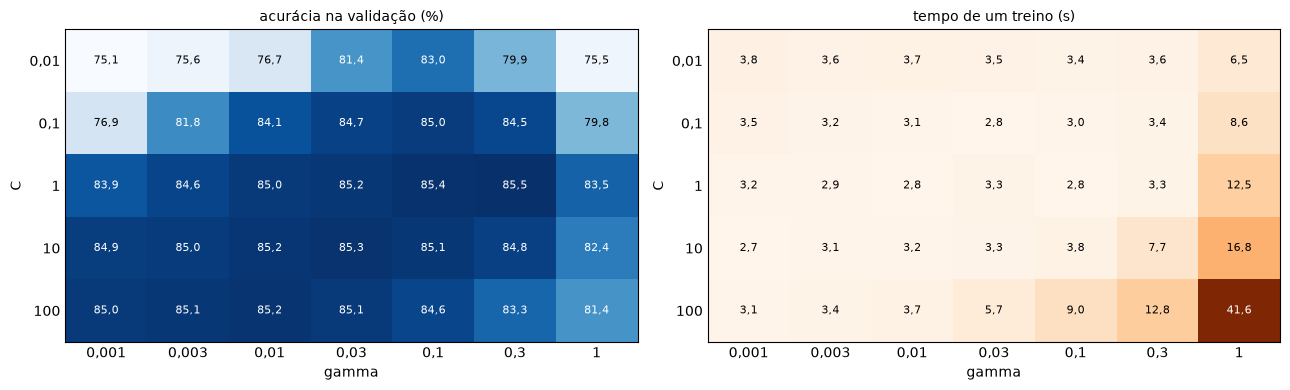

In [5]:
def mapa_calor(ax, valores, titulo, cmap, formato):
    tabela = cv.pivot(index="C", columns="gamma", values=valores)
    im = ax.imshow(tabela, cmap=cmap, aspect="auto")
    ax.set_xticks(range(tabela.shape[1]), [f"{g:g}".replace(".", ",") for g in tabela.columns])
    ax.set_yticks(range(tabela.shape[0]), [f"{c:g}".replace(".", ",") for c in tabela.index])
    ax.set_xlabel("gamma")
    ax.set_ylabel("C")
    ax.set_title(titulo, fontsize=10)
    ax.tick_params(length=0)
    limite = tabela.values.min() + 0.6 * (tabela.values.max() - tabela.values.min())
    for i in range(tabela.shape[0]):
        for j in range(tabela.shape[1]):
            v = tabela.iloc[i, j]
            ax.text(j, i, formato(v), ha="center", va="center", fontsize=8,
                    color="white" if v > limite else "black")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
cv["acc"] = 100 * cv["mean_test_score"]
mapa_calor(ax1, "acc", "acurácia na validação (%)", "Blues", lambda v: f"{v:.1f}".replace(".", ","))
mapa_calor(ax2, "mean_fit_time", "tempo de um treino (s)", "Oranges", lambda v: f"{v:.1f}".replace(".", ","))
plt.tight_layout()
plt.show()

A melhor combinação na validação é **C = 1 e gamma = 0,3** (85,45%), mas o mapa é um platô: 13 das 35 combinações ficam a até 0,5 ponto dela. O platô corre na diagonal: gamma menor pede C maior. Um gamma pequeno faz cada ponto influenciar uma região grande e deixa a fronteira suave; um C maior cobra mais pelos erros e compensa essa suavidade. As duas combinações levam a fronteiras parecidas.

Nos cantos, o modelo falha de dois jeitos. Com C e gamma pequenos (canto superior esquerdo), a fronteira é tão suave e tolerante que o modelo responde `<=50K` para quase todos: 75,1%, o mesmo que o chute. Com gamma = 1 (última coluna), a acurácia cai em qualquer C: é o sobreajuste, mostrado no gráfico abaixo.

O tempo de um treino fica perto de 3 s em quase todo o mapa, mas cresce quando C e gamma crescem juntos, até 41,6 s em C = 100 e gamma = 1, mais de 10 vezes o típico. O mapa inteiro levou 41 minutos, dos quais só 17 foram de treino: a avaliação também conta, porque a SVM prevê comparando cada pessoa com todos os vetores de suporte, e o mapa avaliou cada combinação também nas partes de treino para o gráfico abaixo.

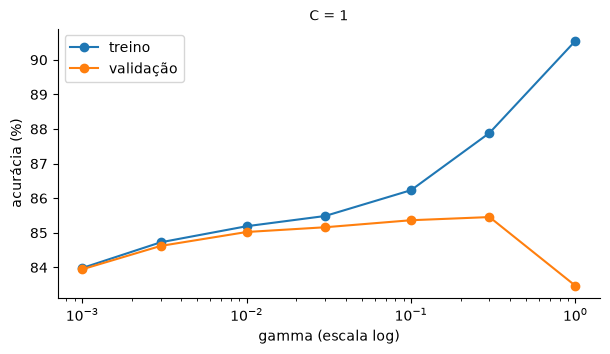

In [6]:
C_melhor = melhor["C"]
linha = cv[cv["C"] == C_melhor].sort_values("gamma")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(linha["gamma"], 100 * linha["mean_train_score"], marker="o", label="treino")
ax.plot(linha["gamma"], 100 * linha["mean_test_score"], marker="o", label="validação")
ax.set_xscale("log")
ax.set_xlabel("gamma (escala log)")
ax.set_ylabel("acurácia (%)")
ax.set_title(f"C = {C_melhor:g}", fontsize=10)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Com C = 1, a acurácia no treino e na validação andam juntas até gamma = 0,1. A partir daí, o treino continua subindo e a validação para: em gamma = 0,3 a diferença é de 2,4 pontos, e em gamma = 1 o treino chega a 90,5% enquanto a validação cai para 83,5%. Com gamma grande, cada ponto influencia só a sua vizinhança, e a fronteira passa a contornar pessoas do treino uma a uma: o modelo decora em vez de generalizar. A melhor validação (gamma = 0,3) já fica no começo dessa separação.

## 4. A curva do C na SVM linear

Na LinearSVC, o único hiperparâmetro é o C. A curva mostra a acurácia no treino e na validação (5 partes, só com o treino da seed 0) para C de 0,0001 a 100.

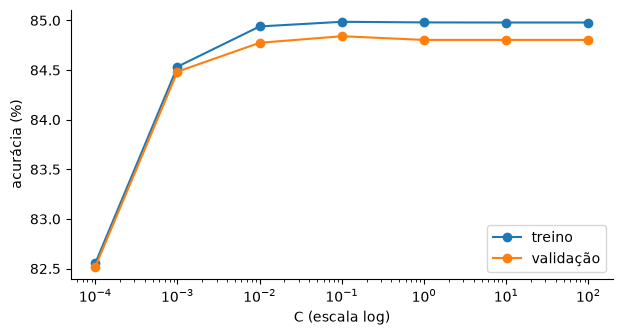

C,0.0001,0.0010,0.0100,0.1000,1.0000,10.0000,100.0000
treino,82.55,84.53,84.94,84.99,84.98,84.98,84.98
validação,82.52,84.48,84.77,84.84,84.80,84.80,84.80


In [7]:
valores_C = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
with threadpool_limits(1):
    treino, validacao = validation_curve(svm.svm_linear(), X_tr, y_tr, param_name="modelo__C",
                                         param_range=valores_C, cv=avaliacao.validacao_cruzada(0), n_jobs=1)
curva_C = pd.DataFrame({"C": valores_C, "treino": 100 * treino.mean(axis=1),
                        "validação": 100 * validacao.mean(axis=1)}).set_index("C")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(curva_C.index, curva_C["treino"], marker="o", label="treino")
ax.plot(curva_C.index, curva_C["validação"], marker="o", label="validação")
ax.set_xscale("log")
ax.set_xlabel("C (escala log)")
ax.set_ylabel("acurácia (%)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()
curva_C.round(2).T

Na SVM linear, a validação fica estável em cerca de 84,8% para C de 0,01 para cima, e o treino acompanha a menos de 0,2 ponto. Não há sobreajuste: uma fronteira reta em 80 colunas é simples demais para decorar 24 mil pessoas. Só um C muito pequeno (0,0001) prejudica, com 82,5%: a margem fica tão larga que o modelo quase não aprende. Por isso a grade da LinearSVC é barata e a escolha do C pouco muda o resultado.

## 5. Com e sem padronização

O mesmo modelo, com e sem a padronização dos 5 atributos numéricos (o one-hot continua nos dois casos). O kernel RBF usa a melhor combinação do mapa.

In [8]:
padronizacao = avaliar({
    "RBF com padronização": svm.svm(**melhor),
    "RBF sem padronização": svm.svm(padronizar=False, **melhor),
    "LinearSVC com padronização": svm.svm_linear(C=1),
    "LinearSVC sem padronização": svm.svm_linear(padronizar=False, C=1),
})
padronizacao

,acurácia,F1 macro,F1 >50K,AUC,falsos positivos,falsos negativos,tempo de treino (s),vetores de suporte
RBF com padronização,85.0,78.9,67.6,87.6,346.0,559.0,12.29,9147.0
RBF sem padronização,80.6,69.3,50.8,82.4,274.0,897.0,33.94,16995.0
LinearSVC com padronização,84.6,78.2,66.5,89.8,351.0,579.0,0.07,NaN
LinearSVC sem padronização,84.6,78.3,66.5,89.6,345.0,581.0,0.05,NaN


Sem padronização, o RBF cai de 85,0% para 80,6% de acurácia, e o F1 da classe >50K de 67,6% para 50,8%: os falsos negativos sobem de 559 para 897. O modelo também fica mais lento (34 s, contra 6 a 12 s com padronização nas medições desta etapa) e passa a usar 16.995 vetores de suporte, 70% do treino. O kernel RBF mede a distância entre pessoas misturando todos os atributos: sem padronização, uma diferença de mil dólares no ganho de capital pesa mais que diferenças em todos os outros atributos juntos, e o kernel praticamente só enxerga o ganho de capital.

Na LinearSVC, a padronização não muda nada (84,6% nos dois casos). O modelo linear multiplica cada atributo por um peso próprio, e um atributo de escala grande simplesmente recebe um peso pequeno. É a diferença entre os dois: o kernel depende de distâncias, a fronteira reta depende de pesos.

## 6. Vetores de suporte

Só os vetores de suporte definem a fronteira. Eles são de dois tipos: os que ficam exatamente sobre a margem e os que ficam dentro dela ou do lado errado, cuja penalidade bate no limite C. A tabela usa o gamma escolhido no mapa e varia o C, treinando no treino inteiro.

In [9]:
linhas = []
for C in svm.GRADE_MAPA["modelo__C"]:
    with threadpool_limits(1):
        inicio = perf_counter()
        modelo = svm.svm(C=C, gamma=melhor["gamma"]).fit(X_tr, y_tr)
        tempo = perf_counter() - inicio
    nucleo = modelo.named_steps["modelo"]
    no_limite = np.isclose(np.abs(nucleo.dual_coef_[0]), C)
    linhas.append({
        "C": C,
        "vetores de suporte": len(nucleo.support_),
        "% do treino": round(100 * len(nucleo.support_) / len(X_tr), 1),
        "sobre a margem": int((~no_limite).sum()),
        "dentro da margem ou do lado errado": int(no_limite.sum()),
        "acurácia no teste (%)": round(100 * modelo.score(X_te, y_te), 1),
        "tempo de treino (s)": round(tempo, 1),
    })
vetores = pd.DataFrame(linhas).set_index("C")
vetores

,vetores de suporte,% do treino,sobre a margem,dentro da margem ou do lado errado,acurácia no teste (%),tempo de treino (s)
C,,,,,,
0.01,11626,48.2,301,11325,80.6,8.4
0.10,9679,40.1,950,8729,84.4,6.2
1.00,9147,37.9,2556,6591,85.0,5.9
10.00,8946,37.1,4124,4822,84.0,20.5
100.00,8261,34.3,4400,3861,82.7,20.7


Com C maior, o número de vetores de suporte cai de 11.626 (48% do treino) para 8.261 (34%), e o tipo muda. Com C = 0,01, quase todos (11.325) estão dentro da margem ou do lado errado: a margem é tão larga que metade do treino cabe nela. Com C = 100, mais da metade (4.400 de 8.261) fica exatamente sobre a margem: o modelo tolera poucos erros e a margem estreita.

A acurácia no teste tem pico em C = 1 (85,0%). Com C = 0,01, o modelo subajusta (80,6%); com C = 100, sobreajusta (82,7%). O tempo de treino sobe de cerca de 6 s (C até 1) para cerca de 20 s (C de 10 para cima).

## 7. Tempo de treino por tamanho do treino

Cada modelo é treinado com os primeiros n exemplos do treino da seed 0, para n de 1.000 a 24.111, num único núcleo. Em escala log-log, uma reta de inclinação 1 significa tempo proporcional a n; inclinação 2, proporcional a n².

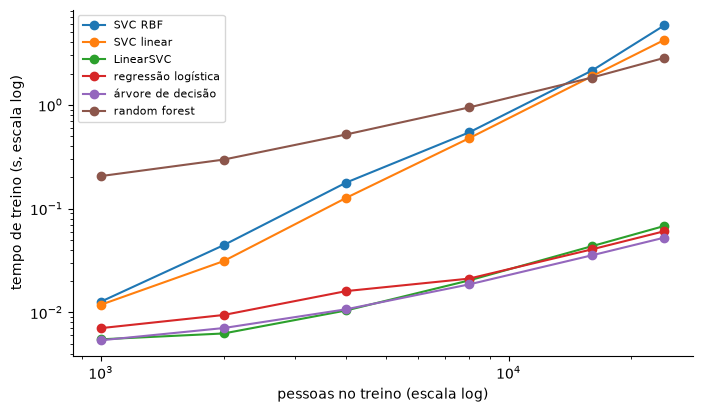

n,1000,2000,4000,8000,16000,24111,inclinação (n ≥ 4.000)
modelo,,,,,,,
SVC RBF,0.013,0.044,0.178,0.542,2.134,5.839,1.93
SVC linear,0.012,0.031,0.127,0.476,1.883,4.226,1.95
LinearSVC,0.005,0.006,0.010,0.020,0.043,0.068,1.05
regressão logística,0.007,0.009,0.016,0.021,0.040,0.061,0.75
árvore de decisão,0.005,0.007,0.011,0.019,0.035,0.053,0.89
random forest,0.206,0.296,0.518,0.943,1.829,2.836,0.94


In [10]:
tamanhos = [1000, 2000, 4000, 8000, 16000, len(X_tr)]
modelos_tempo = {
    "SVC RBF": lambda: svm.svm(**melhor),
    "SVC linear": lambda: svm.svm("linear", C=1),
    "LinearSVC": lambda: svm.svm_linear(C=1),
    "regressão logística": lambda: Pipeline([("prep", avaliacao.preprocessador()), ("modelo", LogisticRegression(max_iter=1000))]),
    "árvore de decisão": lambda: Pipeline([("prep", avaliacao.preprocessador()), ("modelo", DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=0))]),
    "random forest": lambda: Pipeline([("prep", avaliacao.preprocessador()), ("modelo", RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=1))]),
}
linhas = []
for nome, fabrica in modelos_tempo.items():
    for n in tamanhos:
        with threadpool_limits(1):
            inicio = perf_counter()
            fabrica().fit(X_tr.iloc[:n], y_tr.iloc[:n])
            linhas.append({"modelo": nome, "n": n, "tempo (s)": perf_counter() - inicio})
tempos = pd.DataFrame(linhas)
tempos.to_csv(config.RESULTS_DIR / "svm_tempo_por_tamanho.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
inclinacoes = {}
for nome, grupo in tempos.groupby("modelo", sort=False):
    ax.plot(grupo["n"], grupo["tempo (s)"], marker="o", label=nome)
    maiores = grupo[grupo["n"] >= 4000]
    inclinacoes[nome] = np.polyfit(np.log(maiores["n"]), np.log(maiores["tempo (s)"]), 1)[0]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("pessoas no treino (escala log)")
ax.set_ylabel("tempo de treino (s, escala log)")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

resumo_tempo = tempos.pivot(index="modelo", columns="n", values="tempo (s)").loc[list(modelos_tempo)].round(3)
resumo_tempo["inclinação (n ≥ 4.000)"] = pd.Series(inclinacoes).round(2)
resumo_tempo

As duas SVCs têm inclinação de cerca de 1,9 no gráfico log-log: o tempo cresce com o quadrado do número de pessoas no treino. Dobrar o treino quadruplica o tempo. A LinearSVC tem inclinação 1,05, tempo proporcional a n; a regressão logística, a árvore e a Random Forest ficam abaixo de 1, porque nos tamanhos pequenos um custo fixo pesa mais que os dados.

Com 24.111 pessoas, o SVC RBF leva 5,8 s e a LinearSVC 0,07 s, cerca de 85 vezes menos. A Random Forest é mais lenta que o SVC nos tamanhos pequenos; as curvas se cruzam entre 8 e 16 mil pessoas, e daí em diante o SVC é o mais lento. Seguindo a regra do quadrado, o mesmo SVC levaria cerca de 100 s com 100 mil pessoas e quase 3 horas com 1 milhão. Nesta base, o custo da SVM é administrável; numa base dez vezes maior, a LinearSVC ou uma aproximação do kernel seriam necessárias.

## 8. Pesos por classe

Com `class_weight="balanced"`, um erro numa pessoa >50K custa cerca de 3 vezes mais que um erro numa pessoa `<=50K` (o inverso da proporção das classes). O modelo passa a ter mais cuidado com a classe pequena. Mesma combinação de C e gamma nos dois casos.

,acurácia,F1 macro,F1 >50K,AUC,falsos positivos,falsos negativos,tempo de treino (s),vetores de suporte
RBF sem pesos,85.0,78.9,67.6,87.6,346.0,559.0,6.38,9147.0
RBF balanced,80.9,77.4,68.6,88.8,907.0,245.0,6.85,10270.0


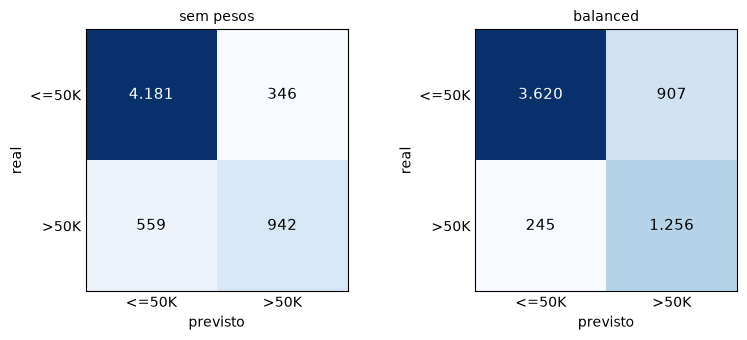

In [11]:
pesos = avaliar({
    "RBF sem pesos": svm.svm(**melhor),
    "RBF balanced": svm.svm(class_weight="balanced", **melhor),
})
display(pesos)

fig, eixos = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, (nome, modelo) in zip(eixos, {"sem pesos": svm.svm(**melhor),
                                      "balanced": svm.svm(class_weight="balanced", **melhor)}.items()):
    matriz = confusion_matrix(y_te, modelo.fit(X_tr, y_tr).predict(X_te))
    ax.imshow(matriz, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matriz[i, j]:,}".replace(",", "."), ha="center", va="center",
                    color="white" if matriz[i, j] > matriz.max() / 2 else "black", fontsize=11)
    ax.set_xticks([0, 1], ["<=50K", ">50K"])
    ax.set_yticks([0, 1], ["<=50K", ">50K"])
    ax.set_xlabel("previsto")
    ax.set_ylabel("real")
    ax.set_title(nome, fontsize=10)
    ax.tick_params(length=0)
plt.tight_layout()
plt.show()

Com os pesos, os falsos negativos caem de 559 para 245: o modelo passa a encontrar 1.256 das 1.501 pessoas que ganham mais de 50 mil (84%), contra 942 (63%) sem pesos. Em troca, os falsos positivos sobem de 346 para 907, e a acurácia cai de 85,0% para 80,9%. O F1 da classe >50K sobe um ponto (67,6% para 68,6%), o F1 macro cai 1,5 ponto e a AUC sobe de 87,6% para 88,8%.

Nenhuma das duas versões é melhor em absoluto: é uma troca de um tipo de erro pelo outro. Se o objetivo for encontrar o máximo de pessoas de renda alta (uma campanha, por exemplo), a versão com pesos é melhor, apesar da acurácia menor. Se cada falso positivo tiver custo alto, a versão sem pesos é melhor. É mais um caso em que a acurácia sozinha não decide.

**Resultado.** O que o estudo na seed 0 mostrou:

- **Como a SVM decide:** pela distância à fronteira, não por probabilidade. Um terço das pessoas do teste cai na faixa da margem, onde as classes se misturam.
- **Kernels:** todos entre 84,5% e 85,1% com C = 1; as fronteiras curvas ganham cerca de meio ponto. A LinearSVC dá o mesmo resultado que a SVC linear, 60 vezes mais rápido.
- **Mapa C × gamma:** um platô de cerca de 85% na diagonal (gamma menor pede C maior); melhor ponto em C = 1 e gamma = 0,3. Gamma = 1 sobreajusta; C e gamma pequenos caem no chute.
- **SVM linear:** estável para C ≥ 0,01, sem sobreajuste.
- **Padronização:** essencial para o RBF (85,0% contra 80,6%), indiferente para a LinearSVC.
- **Vetores de suporte:** de 34% a 48% do treino; com C maior, menos vetores e mais deles sobre a margem.
- **Tempo:** o SVC cresce com n² (inclinação 1,9), a LinearSVC com n.
- **Pesos por classe:** trocam 314 falsos negativos por 561 falsos positivos; a acurácia cai, o F1 da classe >50K e a AUC sobem.

**Grade para a comparação em 10 seeds** (etapa 5), escolhida a partir do mapa:

- **SVC RBF:** C ∈ {0,1; 1; 10; 100} × gamma ∈ {0,01; 0,03; 0,1; 0,3}, 16 combinações. Cobre o platô e deixa de fora os cantos ruins: gamma = 1 (sobreajuste e o treino mais caro) e C = 0,01 (subajuste).
- **LinearSVC:** C ∈ {0,001; 0,01; 0,1; 1; 10}.
- **SVC polinomial:** grau ∈ {2, 3} × C ∈ {0,1; 1; 10}.
- **SVC RBF com pesos por classe:** os mesmos C e gamma escolhidos em cada seed, sem nova busca.

Um ponto a observar: a busca escolhe pela acurácia, e o gamma alto que ela prefere teve AUC menor (87,6%) que a da SVM linear (89,8%) nesta divisão. A etapa 5 mostra se isso se repete nas 10 seeds.